# Check NCBI data

All the sequences data were retrived from NCBI Virus as of 2025-03-10

In [2]:
import pandas as pd
from Bio import SeqIO, Entrez
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
mpl.rcParams['svg.fonttype'] = 'none'
# Path to your Arial.ttf file
arial_font_path = '/Users/skawakubo/python/fonts/Arial.ttf'
# Create a FontProperties object for the Arial font
arial_font = FontProperties(fname=arial_font_path)
mpl.rcParams['font.family'] = arial_font.get_name()
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

In [3]:
stem_dir_path = '/Users/skawakubo/Dropbox/TheSatoLab/Izumi_FIP/github_repo/FCoV-evolution/'

In [4]:
def fasta_to_dataframe(fasta_file):
    ids = []
    sequences = []
    for record in SeqIO.parse(fasta_file, "fasta"):
        ids.append(record.id)
        sequences.append(str(record.seq))

    df = pd.DataFrame({
        "ID": ids,
        "seq": sequences
    })
    return df

In [5]:
# Read the fasta file
FCoV_NCBI_seq_path = '../../sequence_data/NCBI_Virus_250310/sequences.fasta'
FCoV_NCBI_seq = fasta_to_dataframe(FCoV_NCBI_seq_path)
FCoV_NCBI_seq.rename(columns={"ID": "Accession"}, inplace=True)
FCoV_NCBI_seq

,Accession,seq
0,NC_002306.3,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PV135972.1,TTTCTTAACACTCTAAGTTTTATAGTCACTAACCAACATGTGATTG...
2,PQ641430.1,GCTATAACAGCCATTAATCAAACTGATCTGTTTGAATTTGTAAATC...
3,PQ641431.1,GCTATAACAGCCGTTAATCAGACTGATTTGTTTGAGTTTGTAACTC...
4,PQ641432.1,GCTATAACTTCTGTTAATCAAACTGATCTGTTTGAGTTTGTAAATC...
...,...,...
4069,A22378.1,TAAATTATATGTTTGTGAATGACCTCACGTTGCATTTTGTAGACCC...
4070,M23694.1,TGGAGGCATACACAGATGTGTTTGATGACACACAGGTTGAGATGAT...
4071,X66718.1,GATGACACACAGGTTGAGATGATCGATGAGGTAACGAACTAAACGC...
4072,X56496.1,AAACCAAGGCATATAATCCCGACGAAGCATTTTTGGTTTGAACTAA...


In [8]:
# Read the metadata
FCoV_NCBI_meta_path = stem_dir_path + 'sequence_data/NCBI_Virus_250310/sequences.tsv'
FCoV_NCBI_meta = pd.read_csv(FCoV_NCBI_meta_path, sep="\t")
FCoV_NCBI_meta

,Accession,Organism_Name,GenBank_RefSeq,Assembly,SRA_Accession,Submitters,Organization,Org_location,Release_Date,Isolate,...,Nuc_Completeness,Genotype,Publications,Geo_Location,Country,USA,Host,Tissue_Specimen_Source,Collection_Date,GenBank_Title
0,NC_002306.3,Feline infectious peritonitis virus,RefSeq,GCF_000856025.1,NaN,"Haijema,B.J., de Groot-Mijnes,J.D.F., Vennema,...","National Center for Biotechnology Information,...",USA,2000-05-11,79-1146,...,complete,2,NaN,USA,USA,NaN,NaN,NaN,NaN,"Feline infectious peritonitis virus, complete ..."
1,PV135972.1,Feline coronavirus,GenBank,NaN,NaN,"Cretu,D.M., Baraitareanu,S., Gurau,R.M.","USAMV Bucharest, Infectious Disease",Romania,2025-02-26,RO-FCOVS4-2025,...,partial,NaN,NaN,Romania,Romania,NaN,Felis catus,feces,2023-03-14,Feline coronavirus isolate RO-FCOVS4-2025 ORF3...
2,PQ641430.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW12/66,...,partial,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW12/66 spike prote...
3,PQ641431.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW16/66,...,partial,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW16/66 spike prote...
4,PQ641432.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW1206/66,...,partial,NaN,NaN,Thailand,Thailand,NaN,Felis catus,NaN,2023,Feline coronavirus isolate MW1206/66 spike pro...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4069,A22378.1,Feline infectious peritonitis virus,GenBank,set:A22378,NaN,"Vennema,H., Rottier,P.J.",NaN,NaN,1994-10-20,NaN,...,partial,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Feline Infectious Virus (FIPV) genes M and N
4070,M23694.1,Feline infectious peritonitis virus,GenBank,set:M23694,NaN,"De Groot,R.J., Andeweg,A.C., Horzinek,M.C., Sp...",NaN,NaN,1993-08-02,NaN,...,partial,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus ORF1 and O...
4071,X66718.1,Feline coronavirus,GenBank,set:X66718,NaN,"Vennema,H., Rossen,J.W., Wesseling,J., Horzine...","H. Vennema, University of Utrecht, Dept. of Vi...",Netherlands,1993-05-11,FECV WSU 79-1683,...,partial,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline coronavirus mRNA for ORF6a and ORF6b
4072,X56496.1,Feline infectious peritonitis virus,GenBank,set:X56496,NaN,"Vennema,H., de Groot,R.J., Harbour,D.A., Horzi...","Vennema H., Department of Virology, Institute ...",Netherlands,1991-03-25,WSU 79-1146,...,partial,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus (FIPV) gen...


In [9]:
# Merge the metadata and the sequence
FCoV_NCBI = pd.merge(FCoV_NCBI_meta, FCoV_NCBI_seq, on="Accession")
FCoV_NCBI

,Accession,Organism_Name,GenBank_RefSeq,Assembly,SRA_Accession,Submitters,Organization,Org_location,Release_Date,Isolate,...,Genotype,Publications,Geo_Location,Country,USA,Host,Tissue_Specimen_Source,Collection_Date,GenBank_Title,seq
0,NC_002306.3,Feline infectious peritonitis virus,RefSeq,GCF_000856025.1,NaN,"Haijema,B.J., de Groot-Mijnes,J.D.F., Vennema,...","National Center for Biotechnology Information,...",USA,2000-05-11,79-1146,...,2,NaN,USA,USA,NaN,NaN,NaN,NaN,"Feline infectious peritonitis virus, complete ...",ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PV135972.1,Feline coronavirus,GenBank,NaN,NaN,"Cretu,D.M., Baraitareanu,S., Gurau,R.M.","USAMV Bucharest, Infectious Disease",Romania,2025-02-26,RO-FCOVS4-2025,...,NaN,NaN,Romania,Romania,NaN,Felis catus,feces,2023-03-14,Feline coronavirus isolate RO-FCOVS4-2025 ORF3...,TTTCTTAACACTCTAAGTTTTATAGTCACTAACCAACATGTGATTG...
2,PQ641430.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW12/66,...,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW12/66 spike prote...,GCTATAACAGCCATTAATCAAACTGATCTGTTTGAATTTGTAAATC...
3,PQ641431.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW16/66,...,NaN,NaN,Thailand,Thailand,NaN,Felis catus,feces,2023,Feline coronavirus isolate MW16/66 spike prote...,GCTATAACAGCCGTTAATCAGACTGATTTGTTTGAGTTTGTAACTC...
4,PQ641432.1,Feline coronavirus,GenBank,NaN,NaN,"Pongsiwat,S., Bhusri,B., Tangsudjai,S., Saechi...","Faculty of Veterinary Science, Mahidol Univers...",Thailand,2025-01-28,MW1206/66,...,NaN,NaN,Thailand,Thailand,NaN,Felis catus,NaN,2023,Feline coronavirus isolate MW1206/66 spike pro...,GCTATAACTTCTGTTAATCAAACTGATCTGTTTGAGTTTGTAAATC...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4069,A22378.1,Feline infectious peritonitis virus,GenBank,set:A22378,NaN,"Vennema,H., Rottier,P.J.",NaN,NaN,1994-10-20,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Feline Infectious Virus (FIPV) genes M and N,TAAATTATATGTTTGTGAATGACCTCACGTTGCATTTTGTAGACCC...
4070,M23694.1,Feline infectious peritonitis virus,GenBank,set:M23694,NaN,"De Groot,R.J., Andeweg,A.C., Horzinek,M.C., Sp...",NaN,NaN,1993-08-02,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus ORF1 and O...,TGGAGGCATACACAGATGTGTTTGATGACACACAGGTTGAGATGAT...
4071,X66718.1,Feline coronavirus,GenBank,set:X66718,NaN,"Vennema,H., Rossen,J.W., Wesseling,J., Horzine...","H. Vennema, University of Utrecht, Dept. of Vi...",Netherlands,1993-05-11,FECV WSU 79-1683,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline coronavirus mRNA for ORF6a and ORF6b,GATGACACACAGGTTGAGATGATCGATGAGGTAACGAACTAAACGC...
4072,X56496.1,Feline infectious peritonitis virus,GenBank,set:X56496,NaN,"Vennema,H., de Groot,R.J., Harbour,D.A., Horzi...","Vennema H., Department of Virology, Institute ...",Netherlands,1991-03-25,WSU 79-1146,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,Feline infectious peritonitis virus (FIPV) gen...,AAACCAAGGCATATAATCCCGACGAAGCATTTTTGGTTTGAACTAA...


In [10]:
print(FCoV_NCBI["Organism_Name"].value_counts())

Organism_Name
Feline coronavirus                     3888
Feline infectious peritonitis virus     151
Acinonyx jubatus coronavirus              9
Feline coronavirus UU54                   1
Feline coronavirus UU40                   1
Feline coronavirus UU9                    1
Feline coronavirus UU3                    1
Feline coronavirus UU2                    1
Feline coronavirus UU10                   1
Feline coronavirus UU16                   1
Feline coronavirus UU15                   1
Feline coronavirus UU5                    1
Feline coronavirus UU8                    1
Feline coronavirus UU4                    1
Feline coronavirus UU7                    1
Feline coronavirus UU11                   1
Feline coronavirus RM                     1
Feline coronavirus UU23                   1
Feline coronavirus UU47                   1
Feline coronavirus UU34                   1
Feline coronavirus UU31                   1
Feline coronavirus UU24                   1
Feline coronavirus

In [11]:
print(FCoV_NCBI["Tissue_Specimen_Source"].value_counts())

Tissue_Specimen_Source
feces                       999
abdominal cavity            665
feces, abdominal cavity     108
blood                        83
lung                         71
lymph                        43
liver, abdominal cavity      40
kidney, abdominal cavity     27
brain                        12
spleen, abdominal cavity     10
eye                           2
spinal cord                   1
cerebrospinal fluid           1
tonsil                        1
heart                         1
Name: count, dtype: int64


In [12]:
print(FCoV_NCBI['Genotype'].value_counts())
# number of nan values in the Genotype column
#FCoV_NCBI['Genotype'].isnull().sum()

Genotype
1          298
I          246
type I      61
type 1      50
II          19
2            5
type II      2
Name: count, dtype: int64


In [13]:
# select only the important columns
FCoV_NCBI_selected = FCoV_NCBI[["Accession", "Isolate", "Collection_Date", "Country", "Host", "Tissue_Specimen_Source", "Length", "seq"]]
FCoV_NCBI_selected

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,seq
0,NC_002306.3,79-1146,NaN,USA,NaN,NaN,29355,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PV135972.1,RO-FCOVS4-2025,2023-03-14,Romania,Felis catus,feces,687,TTTCTTAACACTCTAAGTTTTATAGTCACTAACCAACATGTGATTG...
2,PQ641430.1,MW12/66,2023,Thailand,Felis catus,feces,103,GCTATAACAGCCATTAATCAAACTGATCTGTTTGAATTTGTAAATC...
3,PQ641431.1,MW16/66,2023,Thailand,Felis catus,feces,103,GCTATAACAGCCGTTAATCAGACTGATTTGTTTGAGTTTGTAACTC...
4,PQ641432.1,MW1206/66,2023,Thailand,Felis catus,NaN,103,GCTATAACTTCTGTTAATCAAACTGATCTGTTTGAGTTTGTAAATC...
...,...,...,...,...,...,...,...,...
4069,A22378.1,NaN,NaN,NaN,NaN,NaN,2517,TAAATTATATGTTTGTGAATGACCTCACGTTGCATTTTGTAGACCC...
4070,M23694.1,NaN,NaN,NaN,NaN,NaN,1272,TGGAGGCATACACAGATGTGTTTGATGACACACAGGTTGAGATGAT...
4071,X66718.1,FECV WSU 79-1683,NaN,NaN,NaN,NaN,957,GATGACACACAGGTTGAGATGATCGATGAGGTAACGAACTAAACGC...
4072,X56496.1,WSU 79-1146,NaN,NaN,NaN,NaN,2000,AAACCAAGGCATATAATCCCGACGAAGCATTTTTGGTTTGAACTAA...


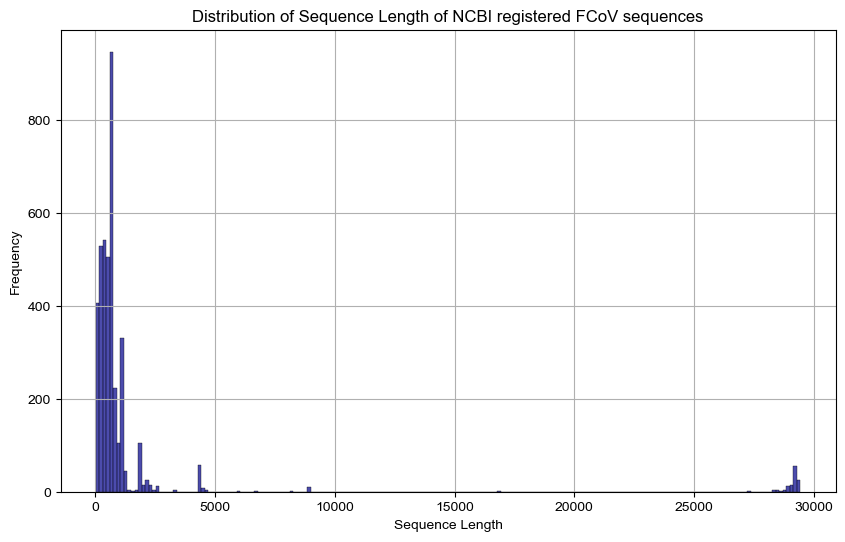

In [14]:
# plot the distribution of the sequence length
plt.figure(figsize=(10, 6))
sns.histplot(FCoV_NCBI_selected['Length'], bins=200, alpha=0.7, color='darkblue')
plt.title("Distribution of Sequence Length of NCBI registered FCoV sequences")
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [15]:
# select only the sequences with the length longer than 25000
FCoV_NCBI_selected_almostfull = FCoV_NCBI_selected[FCoV_NCBI_selected['Length'] > 25000]
FCoV_NCBI_selected_almostfull.reset_index(drop=True, inplace=True)
FCoV_NCBI_selected_almostfull['source'] = 'NCBI'
FCoV_NCBI_selected_almostfull

/var/folders/nj/8kpvd8913_q3ctwwtzf2lr_00000gn/T/ipykernel_34990/1087519566.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  FCoV_NCBI_selected_almostfull['source'] = 'NCBI'


,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,seq,source
0,NC_002306.3,79-1146,NaN,USA,NaN,NaN,29355,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...,NCBI
1,PP254206.1,ZD/22/332i,2022-07-17,India,Felis catus,feces,29229,TCTGCTTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...,NCBI
2,PP254207.1,ZD/22/337i,2022-07-17,India,Felis catus,feces,29229,AACTCTGCTTGGGGTTTAACCTGCCTTGTGCTAGATTTGTCTTCGG...,NCBI
3,PP254208.1,ZD/22/385i,2022-07-19,India,Felis catus,feces,29286,TCTTCATTTAKTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...,NCBI
4,PP254209.1,ZD/22/519i,2022-07-21,India,Felis catus,feces,29221,TCTTCGTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...,NCBI
...,...,...,...,...,...,...,...,...,...
125,EU186072.1,Black,NaN,USA,NaN,NaN,29256,ACTTTTAAAGTAAAGTGAGTGTAGCTGGGCTATAACTCTTCATTTA...,NCBI
126,DQ286389.1,NaN,NaN,USA,NaN,NaN,28632,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...,NCBI
127,DQ848678.1,NaN,NaN,NaN,NaN,abdominal cavity,29277,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTC...,NCBI
128,DQ010921.1,VR-2202 (P100),NaN,NaN,Felis catus,NaN,29147,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTTTTTTT...,NCBI


In [16]:
FCoV_NCBI_selected_almostfull_meta = FCoV_NCBI_selected_almostfull.drop(columns=['seq'])
FCoV_NCBI_selected_almostfull_meta

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,source
0,NC_002306.3,79-1146,NaN,USA,NaN,NaN,29355,NCBI
1,PP254206.1,ZD/22/332i,2022-07-17,India,Felis catus,feces,29229,NCBI
2,PP254207.1,ZD/22/337i,2022-07-17,India,Felis catus,feces,29229,NCBI
3,PP254208.1,ZD/22/385i,2022-07-19,India,Felis catus,feces,29286,NCBI
4,PP254209.1,ZD/22/519i,2022-07-21,India,Felis catus,feces,29221,NCBI
...,...,...,...,...,...,...,...,...
125,EU186072.1,Black,NaN,USA,NaN,NaN,29256,NCBI
126,DQ286389.1,NaN,NaN,USA,NaN,NaN,28632,NCBI
127,DQ848678.1,NaN,NaN,NaN,NaN,abdominal cavity,29277,NCBI
128,DQ010921.1,VR-2202 (P100),NaN,NaN,Felis catus,NaN,29147,NCBI


In [ ]:
FCoV_NCBI_selected_almostfull_meta.to_csv(stem_dir_path + 'FCoV_NCBI_meta_250726.tsv', sep='\t', index=False)

#### obtain all the (nearly) complete sequence and BLAST again against all the nt database so that we won't miss any sequences that are not labeled as FCoV but actually FCoV.
- We might want to include other <em>Alphacoronavirus-1</em>
<em>Alphacoronavirus-1</em> includes:
   * Feline coronavirus (FCoV) 
   * Canine coronaviruses (CCoV)
   * Transmissible gastroenteritis virus (TGEV) 

- Each has both serotype-1 and -2

# Check original data from Izumi

In [18]:
FCoV_Izumi_seq_path = stem_dir_path + "sequence_data/FCoV_seq_Izumi_v2_250310_renamed_mafft.fasta"
FCoV_Izumi_seq = fasta_to_dataframe(FCoV_Izumi_seq_path)
FCoV_Izumi_seq['seq'] = FCoV_Izumi_seq['seq'].str.upper()
FCoV_Izumi_seq

,ID,seq
0,v11-1_S79,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
1,v8-1_S91,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
2,V7-11_S129,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
3,V6-11_S105,----------------------------------------------...
4,V5-S_S8,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
5,V004,-ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTA...
6,V3-S_S7,------------NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
7,V2-10_S68,----------------------------------------------...
8,V1-10_S56,----------------------------------------------...
9,RGU3-1_S43,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...


In [28]:
FCoV_Izumi_seq['ID'].to_list()

['v11-1_S79',
 'v8-1_S91',
 'V7-11_S129',
 'V6-11_S105',
 'V5-S_S8',
 'V004',
 'V3-S_S7',
 'V2-10_S68',
 'V1-10_S56',
 'RGU3-1_S43',
 'RGU2-1_S31',
 'RGU1-1_S19',
 'H8-10_S44',
 'H7-10_S32',
 'H6-10_S20',
 'H2-10_S116',
 '775024S_S3_L001',
 'IZ_1_S7_L001',
 '771819S_S4_L001',
 'IZ_2_S8_L001']

In [13]:
# merge only the genome data of NCBI and Izumi
FCoV_NCBI_selected_almostfull_for_merge = FCoV_NCBI_selected_almostfull[["Accession", "seq"]]
FCoV_NCBI_selected_almostfull_for_merge.rename(columns={"Accession": "ID"}, inplace=True)

/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_94718/417479005.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  FCoV_NCBI_selected_almostfull_for_merge.rename(columns={"Accession": "ID"}, inplace=True)


In [14]:
# remove '-' from the sequence
FCoV_Izumi_seq_for_merge = FCoV_Izumi_seq.copy()
FCoV_Izumi_seq_for_merge['seq'] = FCoV_Izumi_seq_for_merge['seq'].str.replace("-", "")
FCoV_Izumi_seq_for_merge

,ID,seq
0,v11-1_S79,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
1,v8-1_S91,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
2,V7-11_S129,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
3,V6-11_S105,NNNNNNNNNNNNNNNCGGACACCAACTCGAACTAAACGAAATATTT...
4,V5-S_S8,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
5,V004,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTAT...
6,V3-S_S7,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
7,V2-10_S68,NNNTGGACTGGGTTTAAGACTTCTTGTTGTGGTCTTCATGGCAAAG...
8,V1-10_S56,GACTGGACTGGTTTTAAGACTGCTTGCTGTGGTCTTCATGGCAAAG...
9,RGU3-1_S43,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...


In [15]:
# merge the NCBI and Izumi data
FCoV_all = pd.concat([FCoV_NCBI_selected_almostfull_for_merge, FCoV_Izumi_seq_for_merge], ignore_index=True)
FCoV_all

,ID,seq
0,NC_002306.3,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...
1,PP254206.1,TCTGCTTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
2,PP254207.1,AACTCTGCTTGGGGTTTAACCTGCCTTGTGCTAGATTTGTCTTCGG...
3,PP254208.1,TCTTCATTTAKTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
4,PP254209.1,TCTTCGTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...
...,...,...
145,H2-10_S116,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...
146,775024S_S3_L001,GGACACCAACTCGAACTAAACGAAATATTTGTCTCTCTATGAAACC...
147,IZ_1_S7_L001,TTTACTTTGAGTGGCTTAGTGCTACGTTTGTCTTCGGACACCAACT...
148,771819S_S4_L001,CGGACACCAACTCGAACTAAACGAAATATTTGTCTCTCTATGAAAC...


In [16]:
# count the number of 'N' in each sequence
FCoV_all['N_count'] = FCoV_all['seq'].str.count('N')
FCoV_all

,ID,seq,N_count
0,NC_002306.3,ACTTTTAAAGTAAAGTGAGTGTAGCGTGGCTATAACTCTTCTTTTA...,0
1,PP254206.1,TCTGCTTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...,3853
2,PP254207.1,AACTCTGCTTGGGGTTTAACCTGCCTTGTGCTAGATTTGTCTTCGG...,12
3,PP254208.1,TCTTCATTTAKTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...,3000
4,PP254209.1,TCTTCGTTTGCTTTAACCTGCCTTGTGCTAGATTTGTCTTCGGACA...,2610
...,...,...,...
145,H2-10_S116,NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN...,530
146,775024S_S3_L001,GGACACCAACTCGAACTAAACGAAATATTTGTCTCTCTATGAAACC...,0
147,IZ_1_S7_L001,TTTACTTTGAGTGGCTTAGTGCTACGTTTGTCTTCGGACACCAACT...,0
148,771819S_S4_L001,CGGACACCAACTCGAACTAAACGAAATATTTGTCTCTCTATGAAAC...,0


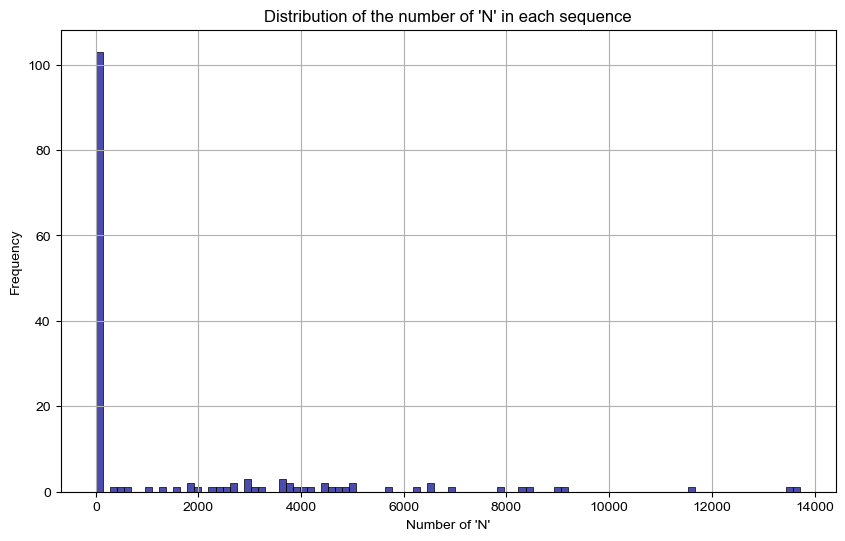

In [17]:
# plot the distribution of the number of 'N' in each sequence
plt.figure(figsize=(10, 6))
sns.histplot(FCoV_all['N_count'], bins=100, alpha=0.7, color='darkblue')
plt.title("Distribution of the number of 'N' in each sequence")
plt.xlabel("Number of 'N'")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [ ]:
# # write the merged data to a fasta file
# # Define the output FASTA file path
# output_file = '/Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/FCoV_full_NCBI_Izumi.fasta'

# # Open the file in write mode
# with open(output_file, 'w') as fasta_file:
#     # Iterate over each row in the DataFrame
#     for index, row in FCoV_all.iterrows():
#         # Write the header line with '>'
#         fasta_file.write(f'>{row["ID"]}\n')
#         # Write the sequence line
#         fasta_file.write(f'{row["seq"]}\n')

In [29]:
# # run the mafft
# !mafft --auto /Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/FCoV_full_NCBI_Izumi.fasta > /Users/skawakubo/Library/CloudStorage/Dropbox/TheSatoLab/Izumi_FIP/sequence_data/FCoV_full_NCBI_Izumi_mafft.fasta

# retrive metadata from NCBI entry


* later rewrite with the new blastn hit

In [18]:
# Retrieve the sequence of the reference genome from NCBI
Entrez.email = "skawakubo@g.ecc.u-tokyo.ac.jp" 

In [19]:
FCoV_acc_list = FCoV_NCBI_selected_almostfull['Accession'].to_list()


In [ ]:
# Retrieve the sequence of the reference genome from NCBI
Entrez.email = "skawakubo@g.ecc.u-tokyo.ac.jp" 


def fetch_genbank_data(accession_id):
    with Entrez.efetch(db="nuccore", id=accession_id, rettype="gb", retmode="text") as handle:
        record = SeqIO.read(handle, "genbank")
    return record

# Accession numbers of genomes to be retrieved
accession_list = ["NC_002306.3", "PP254206.1", "PP254207.1"] 

records = []

for acc in accession_list:
    record = fetch_genbank_data(acc)
    if record:
        records.append(record)
        time.sleep(1)


# handle = Entrez.efetch(db='nuccore', id='NC_002306.3', rettype='gb', retmode='text')
# record = SeqIO.read(handle, "genbank")
# handle.close()
# print(record)

ValueError: No records found in handle

In [ ]:
net_handle = Entrez.efetch(db="nucleotide", id=list(set(Rhino_ACE2_blast_df.sacc)), rettype="gb", retmode="text")
with open('Rhino_ACE2_blast_ntblast_090725.gbk', 'w') as out:
    out.write(net_handle.read())